# Mohs Hardness Prediction — Teacher Notebook
**AOAI Task 3** · Regression · Tabular

### Contains the reference solution. Do not share with students.

| | |
|---|---|
| **Target** | `Hardness` (1–10) |
| **Metric** | **Median Absolute Error** (lower is better) |
| **Baseline (L2 LightGBM)** | ~0.70 OOF MedAE |
| **This solution** | ~0.50 OOF MedAE |

### The two key insights
1. **Loss ≠ metric.** The baseline minimises squared error (predicts the *mean*), but the score is the
*median* absolute error. Switching to an L1 objective (predicts the *median*) is the biggest single win.
2. **The target is discrete.** Hardness takes a handful of values very often (6.0, 5.5, 2.5, ...).
Because the metric is a median, snapping predictions to the nearest frequent value turns
"close" predictions into *exact* ones, which pulls the median error down.

### Notebook structure
1. Setup & data
2. The target is (almost) discrete
3. Features
4. Experiment: loss function vs. metric
5. Post-processing: snapping to frequent values
6. Final model & submission
7. Grading guide

## 1. Setup & Data

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, median_absolute_error

warnings.filterwarnings('ignore')

SEED   = 42
TARGET = 'Hardness'
np.random.seed(SEED)

COMPETITION = 'moth-hardness-task'
CANDIDATES  = [Path(f'/kaggle/input/competitions/{COMPETITION}'), Path(f'/kaggle/input/{COMPETITION}'), Path('data')]
DATA_DIR    = next(p for p in CANDIDATES if p.exists())

train = pd.read_csv(DATA_DIR / 'train.csv')
test  = pd.read_csv(DATA_DIR / 'test.csv')
print(f'Train: {train.shape} | Test: {test.shape}')

Train: (15000, 13) | Test: (10000, 12)


## 2. The Target Is (Almost) Discrete

Unique hardness values: 45
Top 10 values cover 73.0% of the rows

Hardness
6.0    2753
5.5    2077
2.5    1848
3.8    1040
2.0     724
2.8     601
3.0     561
4.0     462
5.0     446
1.5     443
Name: count, dtype: int64


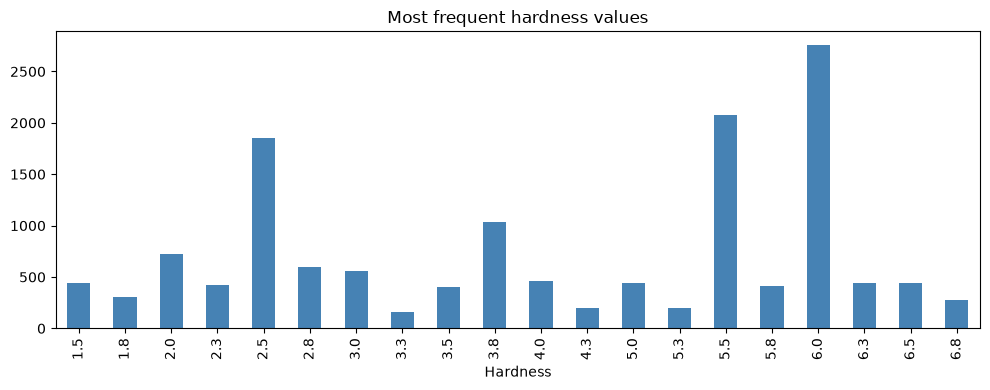


Predicting the training median everywhere gives MedAE = 1.200


In [2]:
vc = train[TARGET].value_counts()
print(f'Unique hardness values: {train[TARGET].nunique()}')
print(f'Top 10 values cover {vc.iloc[:10].sum() / len(train):.1%} of the rows\n')
print(vc.head(10))

fig, ax = plt.subplots(figsize=(10, 4))
vc.head(20).sort_index().plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Most frequent hardness values')
plt.tight_layout()
plt.show()

print(f'\nPredicting the training median everywhere gives MedAE = '
      f'{median_absolute_error(train[TARGET], np.full(len(train), train[TARGET].median())):.3f}')

## 3. Features

Engineered interactions barely move the score for tree models here; we keep the raw features
plus the baseline's interactions so the comparison with the baseline is fair.

In [3]:
def engineer(df):
    df = df.copy()
    df['density_x_ionenergy'] = df['density_Total']         * df['ionenergy_Average']
    df['elneg_x_val_e']       = df['el_neg_chi_Average']    * df['val_e_Average']
    df['atomic_x_density']    = df['atomicweight_Average']  * df['density_Average']
    df['rcov_x_rvdw']         = df['R_cov_element_Average'] * df['R_vdw_element_Average']
    df['zaratio_x_ionenergy'] = df['zaratio_Average']       * df['ionenergy_Average']
    df['density_ratio']       = df['density_Total']      / (df['density_Average'] + 1e-9)
    df['electron_ratio']      = df['allelectrons_Total'] / (df['allelectrons_Average'] + 1e-9)
    return df

train = engineer(train)
test  = engineer(test)

feature_cols = [c for c in train.columns if c not in ['id', TARGET]]
X, y, X_test = train[feature_cols], train[TARGET].values, test[feature_cols]

## 4. Experiment: Loss Function vs. Metric

Same model, same folds — only the `objective` changes.

In [4]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

BASE_PARAMS = dict(
    n_estimators=3000, learning_rate=0.03, num_leaves=31, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=SEED, n_jobs=-1, verbose=-1,
)

def run_cv(params):
    oof, test_pred = np.zeros(len(X)), np.zeros(len(X_test))
    for tr_idx, val_idx in kf.split(X):
        model = lgb.LGBMRegressor(**params)
        model.fit(X.iloc[tr_idx], y[tr_idx],
                  eval_set=[(X.iloc[val_idx], y[val_idx])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[val_idx] = model.predict(X.iloc[val_idx])
        test_pred   += model.predict(X_test) / N_FOLDS
    return oof, test_pred

results = {}
for name, extra in [('L2 (baseline)', {}),
                    ('Huber',         {'objective': 'huber', 'alpha': 1.0}),
                    ('L1',            {'objective': 'l1'})]:
    oof, test_pred = run_cv({**BASE_PARAMS, **extra})
    results[name] = (oof, test_pred)
    print(f'{name:14s} | MedAE {median_absolute_error(y, oof):.4f} | MAE {mean_absolute_error(y, oof):.4f}')

L2 (baseline)  | MedAE 0.7008 | MAE 0.9384


Huber          | MedAE 0.6163 | MAE 0.9095


L1             | MedAE 0.5679 | MAE 0.9009


**Talking point:** squared error is minimised by the conditional *mean*, absolute error by the
conditional *median*. With a skewed, multi-modal target these are far apart.

## 5. Post-Processing: Snapping to Frequent Values

In [5]:
def snap(pred, values, max_dist):
    """Replace a prediction by the nearest frequent value if it is within max_dist of it."""
    dist    = np.abs(pred[:, None] - values[None, :])
    nearest = values[dist.argmin(axis=1)]
    return np.where(dist.min(axis=1) <= max_dist, nearest, pred)

oof_l1, test_l1 = results['L1']

print(f'{"top-N":>6} {"max_dist":>9} {"MedAE":>7}')
for n in (5, 10, 15, 25):
    for max_dist in (0.2, 0.5, 1.0):
        s = snap(oof_l1, vc.index[:n].values, max_dist)
        print(f'{n:>6} {max_dist:>9} {median_absolute_error(y, s):>7.4f}')

 top-N  max_dist   MedAE
     5       0.2  0.5000
     5       0.5  0.5000
     5       1.0  0.5000
    10       0.2  0.5000
    10       0.5  0.5000
    10       1.0  0.5000
    15       0.2  0.5000
    15       0.5  0.5000
    15       1.0  0.5000
    25       0.2  0.5000
    25       0.5  0.5000
    25       1.0  0.5000


Snapping to the ~10 most frequent values gives a clear improvement and is stable across settings.
Because the metric is a median, once more than half of the predictions are *exactly* right or
within one grid step, the score collapses to that step size.

## 6. Final Model & Submission

In [6]:
SNAP_VALUES = vc.index[:10].values
SNAP_DIST   = 0.5

final_oof  = snap(oof_l1,  SNAP_VALUES, SNAP_DIST)
final_test = snap(np.clip(test_l1, 1.0, 10.0), SNAP_VALUES, SNAP_DIST)

print(f'Final OOF MedAE: {median_absolute_error(y, final_oof):.4f}')

submission = pd.DataFrame({'id': test['id'], TARGET: final_test})
submission.to_csv('submission.csv', index=False)
print(f'Saved {len(submission)} predictions to submission.csv')
submission.head()

Final OOF MedAE: 0.5000
Saved 10000 predictions to submission.csv


,id,Hardness
0,15000,5.5
1,15001,5.5
2,15002,5.0
3,15003,2.5
4,15004,5.5


## 7. Grading Guide

| OOF / LB Median AE | What it usually means |
|---|---|
| ≥ 1.0 | Constant or broken predictions |
| 0.65 – 0.75 | Baseline as provided (L2 objective) |
| 0.55 – 0.65 | Switched to L1 / quantile / Huber loss, or tuned heavily |
| 0.50 – 0.55 | L1 loss **and** some handling of the discrete target |
| ≤ 0.50 | Snapping / classification over frequent values, blending |

### What separates strong submissions
1. Reading the metric definition and choosing a matching loss
2. Looking at the target distribution before modelling
3. Validating post-processing on OOF predictions rather than on the leaderboard
4. Honest cross-validation (same folds for all experiments)